# Weekend runs (7–8 Nov): weighted score vs performance in the match-ratio landscape

The weekend queue (`weekend_queue.py`) ran `landscape.py` for ER, Chung–Lu and PAPER: single-run match ratios together with every seed set's features, in cells where outcomes are graded rather than all-or-nothing. The original sections read those results. The separate single-B extension in section 3.1 can collect missing high-value sets on the existing pairs.

**Cells.** Per graph model, three per algorithm, taken from the ER regime map: one where round 1's rules gained a lot over random sets, one moderate and one small. Chung–Lu uses mean degree 10 instead of 8. Each cell runs at the budget where random sets average 50% in that model's regime map. ER also has the same nine cells at the 20% and 80% budgets (one pair each) and a hard cell, mean degree 16 at ρ 0.2 (300 seeds; random sets never reach 50% there).

**Seed sets per pair.** Five pairs per cell and about 480 sets per pair:
- 350 random sets, the first of a pool of 20,000;
- degree-tilted sets: 10 for each γ in −1, −0.5, 0.5, 1, 2 and 3, drawn with probability ∝ degree^γ;
- sets from the pool at 12 quantiles (lowest to highest) of degree, harmonic, pair mass, uniqueness and the frozen score;
- round 1's rules, the best of 100 and of 1,000 random sets by the frozen score, and the best of 1,000 by degree.

**Runs.** FAQ runs every set 3 times with different solver seeds; GOAT and percolation once. On pair 0 of each cell, 100 random sets (spread over the score) also ran on 10 fresh draws of B given A, and for GOAT with the regulariser halved and doubled.

**Outcome and score.** Accuracy on 120 fixed test vertices per pair, never seeds. The *frozen score* (the weighted score) is the pooled four-feature logistic score from `multi_pair_collection`: degree, harmonic, pair mass and uniqueness as z-scores against the pair's pool of random sets of the same budget, with each model's own weights.

In [1]:
import os
import sys
import tempfile
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'sgm_matplotlib_cache'))

import importlib

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / 'experiment_common').is_dir())
if ROOT.name == 'selection_rule_comparison':
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from selection_rule_comparison import landscape as L
L = importlib.reload(L)   # picks up edits to landscape.py without restarting the kernel

pd.set_option('display.max_rows', 300)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 250)

## 1. What was collected

`per_set` has one row per pair and seed set, with its features and its test accuracy on the pair's saved B: `accuracy` averages FAQ's 3 runs, and `accuracy_first` is the first run only (a true single run). `draws` has the 100 redrawn sets of pair 0 on each draw of B (draw 0 is the saved B), and `set_quality` their mean over the 11 draws: as close as we can get to a set's quality as far as graph A can tell.

**Kind of cell:** *standard* is the nine cells at the 50% budget; *level 20%* and *level 80%* are the same cells at other budgets (ER only); *extra* is the hard cell.

In [2]:
sets = L.per_set()
draws = L.draws(sets)
quality = L.set_quality(draws, sets)
display(L.overview(sets))

cells  pairs  seed sets   runs
model    kind                                     
ER       level 20%      9      9       4299   7161
         standard       9     45      21495  35805
         level 80%      9      9       4299   7161
         extra          3      9       4299   7161
Chung-Lu standard       9     45      21495  35805
PAPER    standard       9     45      21495  35805

## 2. Are the outcomes graded?

Histograms of single runs of random sets (first runs). Graded cells fill the grey band (0.2–0.8); all-or-nothing cells pile up at the ends. The ticks at the bottom are the five pairs' means: pairs differ, so every comparison below is made within a pair.

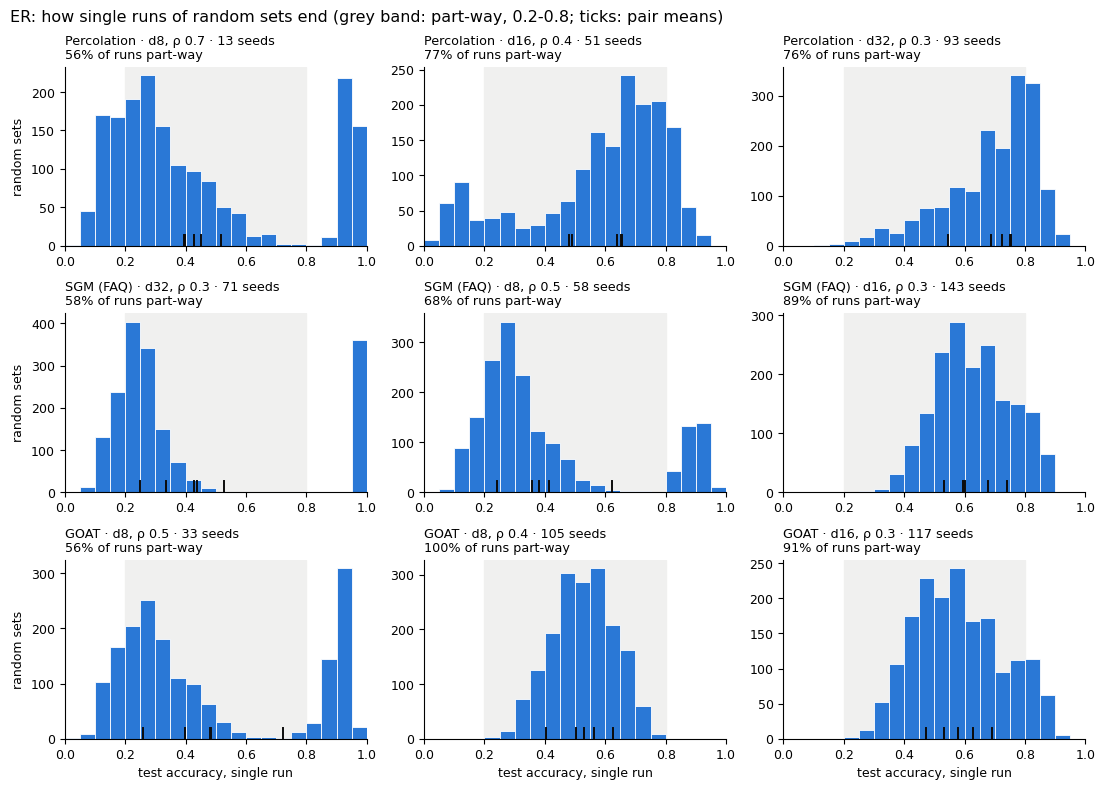

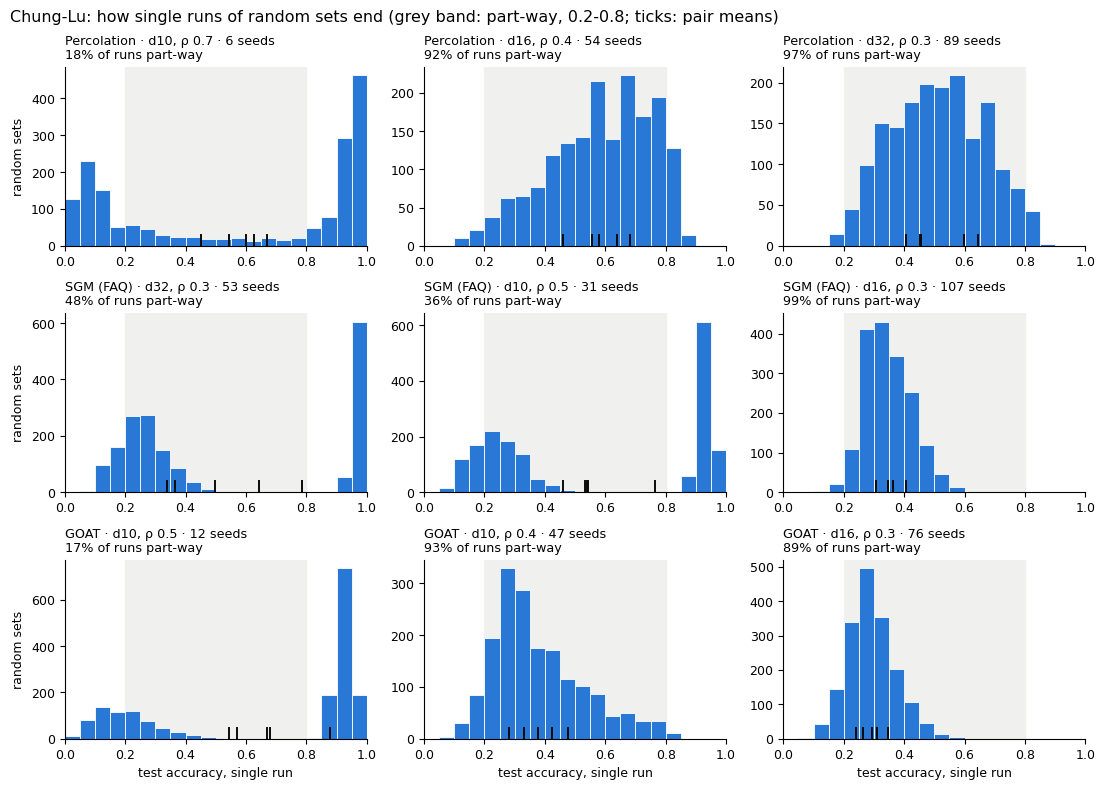

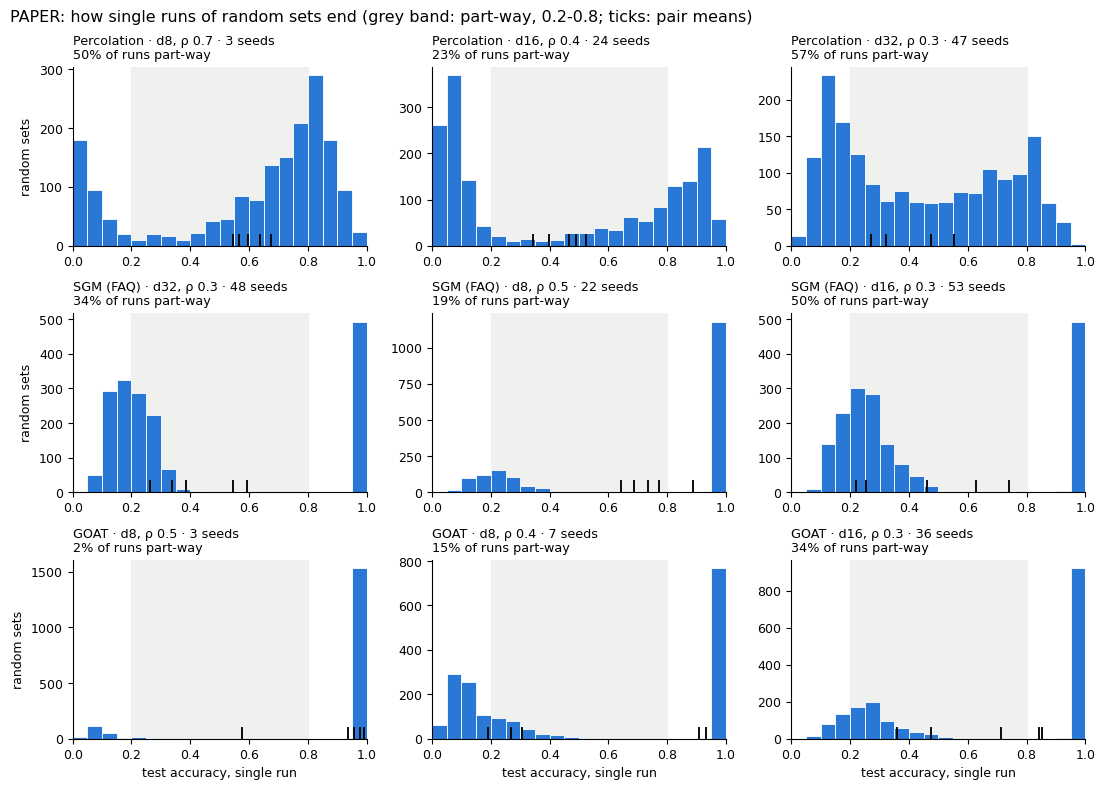

In [3]:
for model in L.MODELS:
    L.plot_distributions(sets, model)
    plt.show()

## 3. Weighted score vs performance

One panel per cell; columns go from the cell where round 1's rules gained most over random sets (left) to the one where they gained least (right).
- **Grey:** every random set on its pair's saved B, all five pairs. For FAQ each point averages its 3 runs.
- **Blue:** the 100 redrawn random sets of pair 0, each averaged over 11 draws of B (its quality as far as graph A can tell).
- **Titles:** Spearman correlation of the score with accuracy over the grey sets (within pair, averaged over pairs), and with the blue means.

A single run on one B is mostly luck of that B (section 4), so the grey clouds stay wide even where the score ranks sets well. The blue points are the fair test of a rule that only sees graph A.

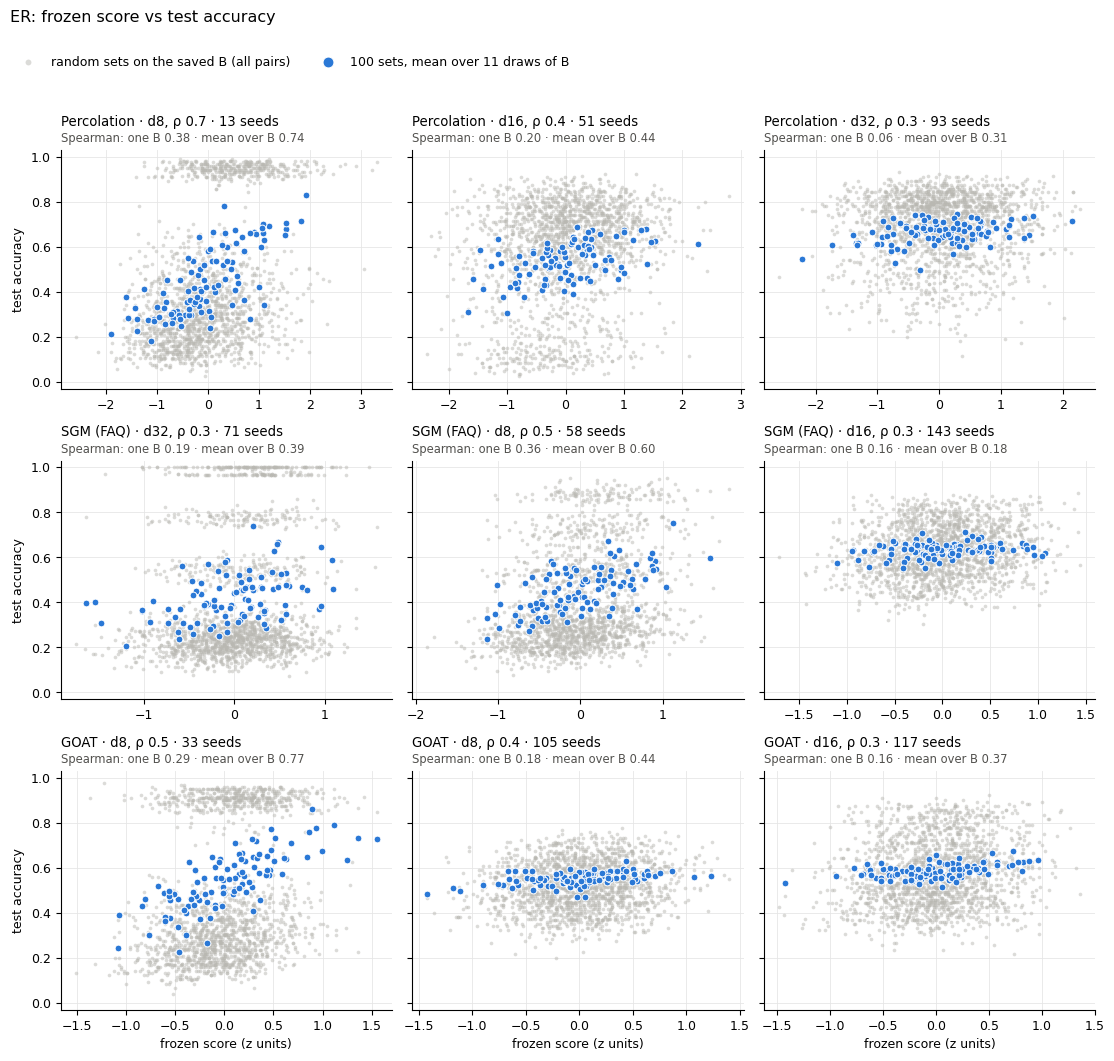

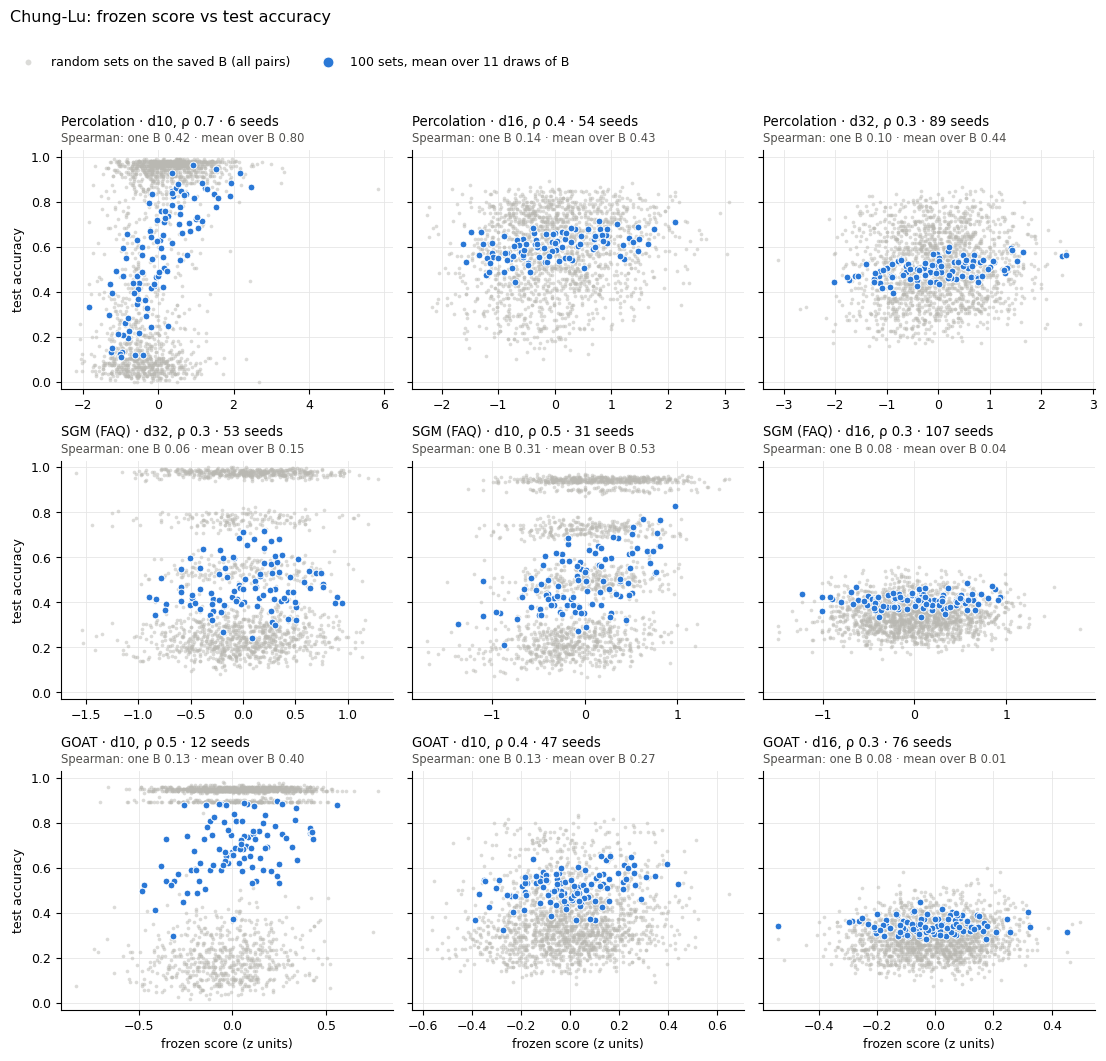

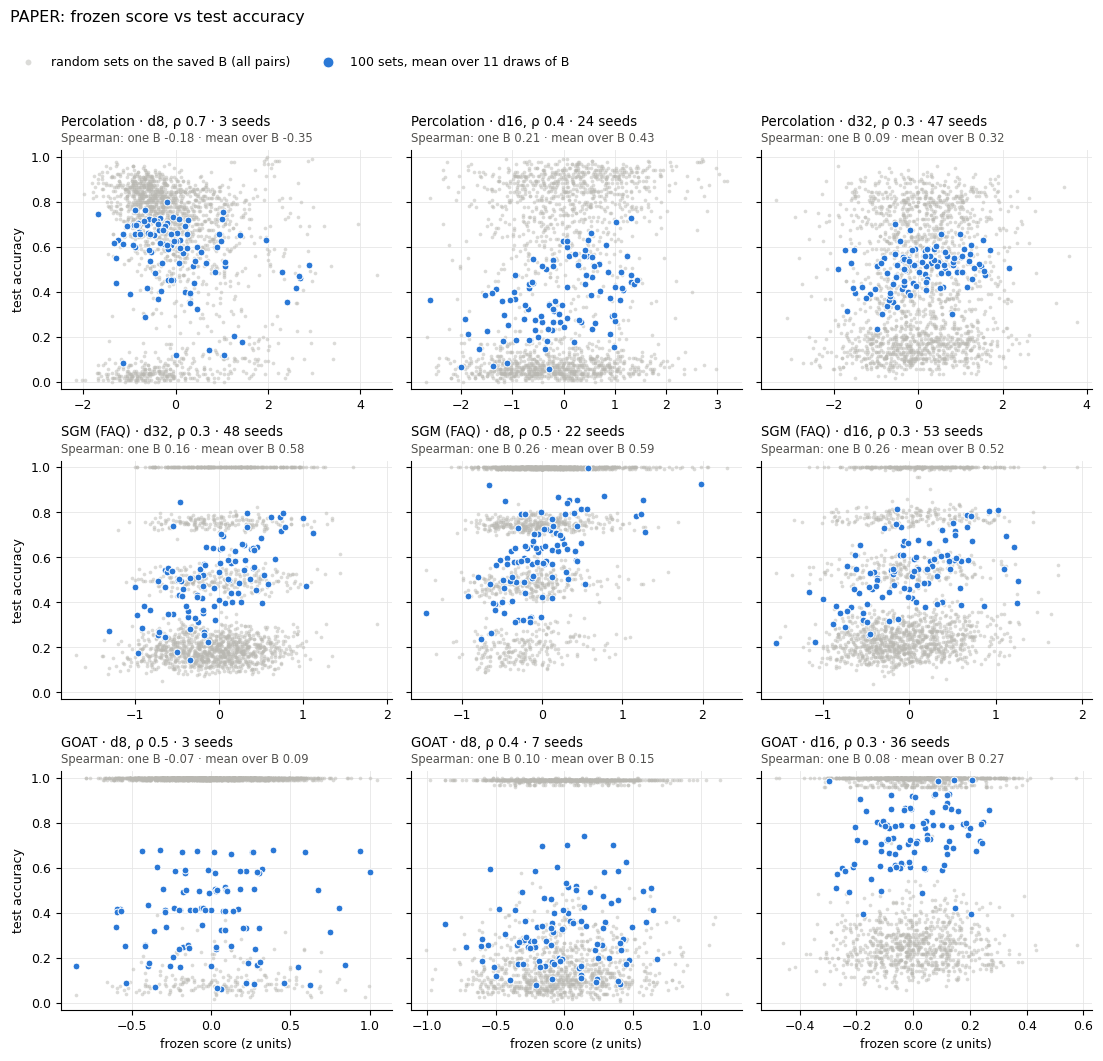

In [4]:
for model in L.MODELS:
    L.plot_score_vs_accuracy(sets, quality, model)
    plt.show()

### 3.1 Wider score range on a single fixed B

These are **separate figures**. The original grey/blue figures above remain unchanged.

Each new panel uses **pair 0's saved A and B**, at the original budget. This is the same A used for the blue 11-B averages above, but here every y-value is one run on the saved B. For FAQ the grey points use the first stored solver run, rather than its three-run average.

- Grey points: the original 350 random sets on this pair.
- Purple/blue symbols: exact top-ten mean total-degree/harmonic sets **among the eligible vertices**, with all 120 fixed test vertices excluded.
- Other colored symbols: ten best-found sets for cut degree, pair mass, uniqueness, coverage and the frozen score, using the same metric-based swap search as the fresh-pair extension.
- Brown circles: intermediate swap-path sets, selected across the frozen-score range.

The full 600-vertex graph is used for every feature. Only seed eligibility is restricted; the test vertices remain in the graph and in evaluation. Normalization uses the **original saved 20,000-set pool statistics**, with the same frozen weights, solver parameters and test vertices.

The search reuses the original landscape sets and the already evaluated A-only constructed sets as candidates. Adaptive learned-selector proposals are excluded. Identical sets reuse the first saved outcome available; all new evaluations use the saved B only. Plotting pools candidates across searches and ranks each metric using graph-A features, with no selection based on matching accuracy.

These figures test whether the narrow random-set range hides a relationship, or whether the frozen score fails to generalize even after widening the range. They do not force a positive or linear trend. Exact additive rankings are distinguished from heuristic best-found results in the legends.

Run only missing evaluations with `RUN_WIDE_COLLECTION = True`; set it to `False` to redraw saved results. Data and PNG/PDF figures are separate under `data/landscape_extremes/`. No additional Bs are generated, and all other sections continue to read the original landscape collection.


Wed 01:16  [1/27] ER Percolation d16 rho0.4, k=51: already done; about 29 min left
Wed 01:16  [2/27] ER Percolation d8 rho0.7, k=13: already done; about 28 min left
Wed 01:16  [3/27] ER Percolation d32 rho0.3, k=93: already done; about 28 min left
Wed 01:16  [4/27] ER SGM (FAQ) d32 rho0.3, k=71: already done; about 27 min left
Wed 01:16  [5/27] ER GOAT d8 rho0.5, k=33: already done; about 25 min left
Wed 01:16  [6/27] ER SGM (FAQ) d8 rho0.5, k=58: already done; about 24 min left
Wed 01:16  [7/27] ER SGM (FAQ) d16 rho0.3, k=143: already done; about 23 min left
Wed 01:16  [8/27] ER GOAT d16 rho0.3, k=117: already done; about 21 min left
Wed 01:16  [9/27] ER GOAT d8 rho0.4, k=105: already done; about 19 min left
Wed 01:16  [10/27] Chung-Lu Percolation d10 rho0.7, k=6: already done; about 19 min left
Wed 01:16  [11/27] Chung-Lu Percolation d16 rho0.4, k=54: already done; about 19 min left
Wed 01:16  [12/27] Chung-Lu SGM (FAQ) d32 rho0.3, k=53: already done; about 17 min left
Wed 01:16  [13

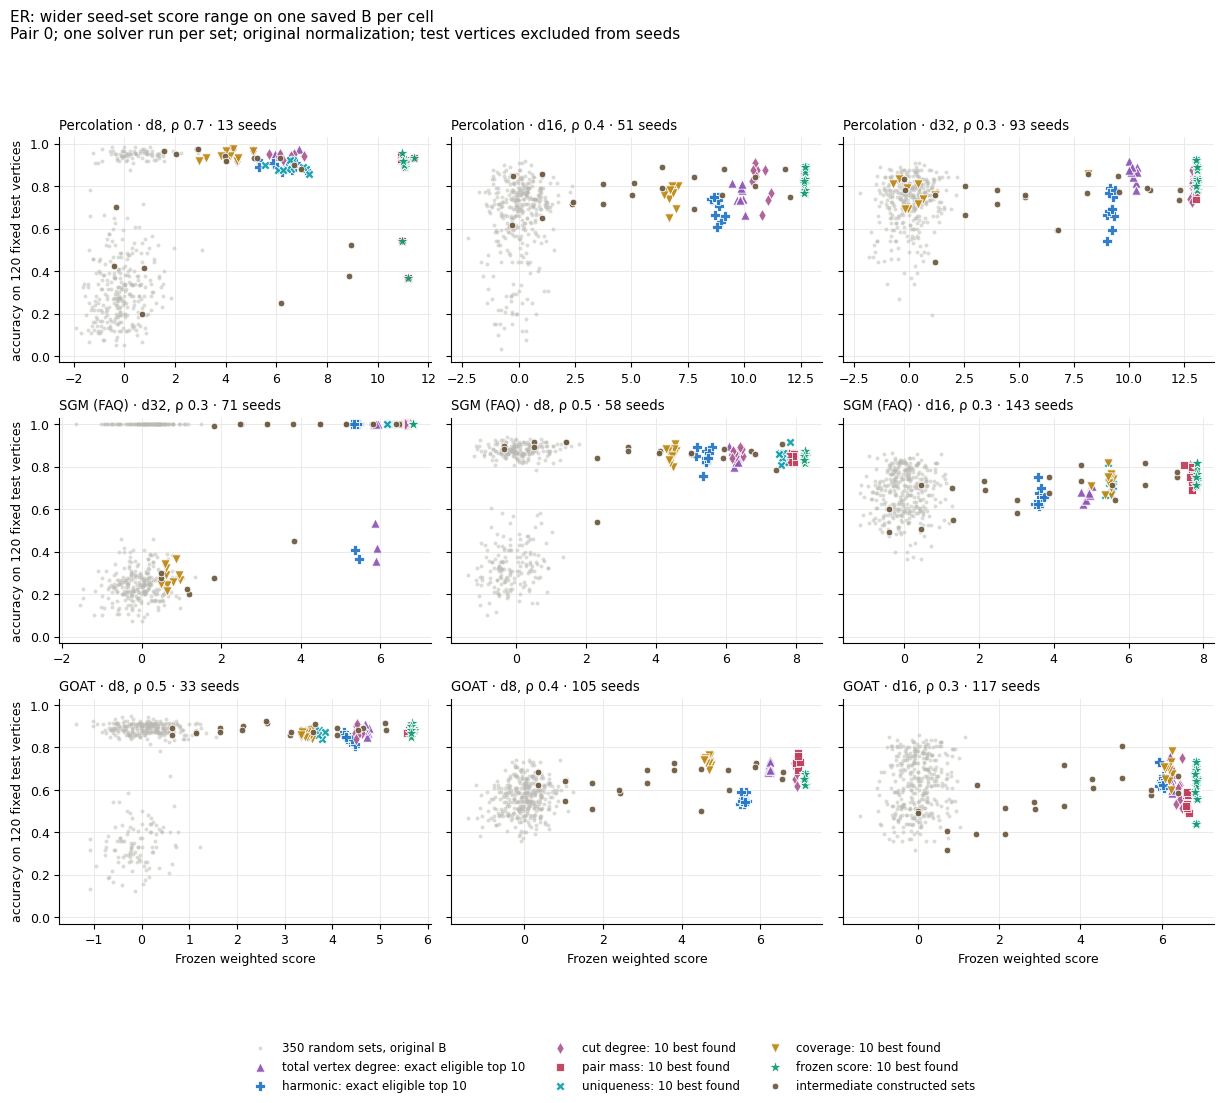

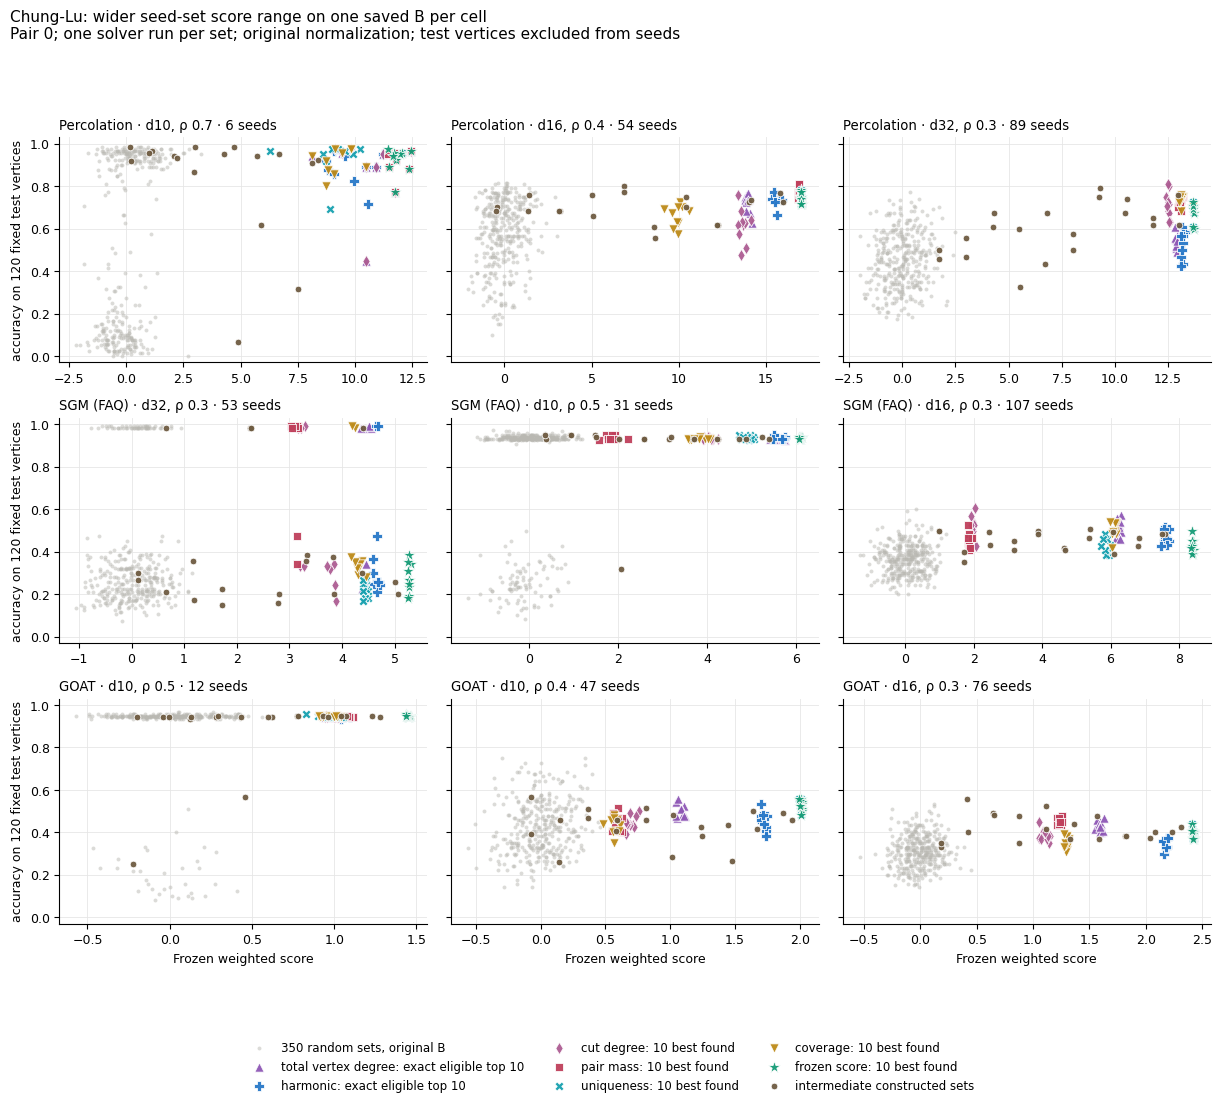

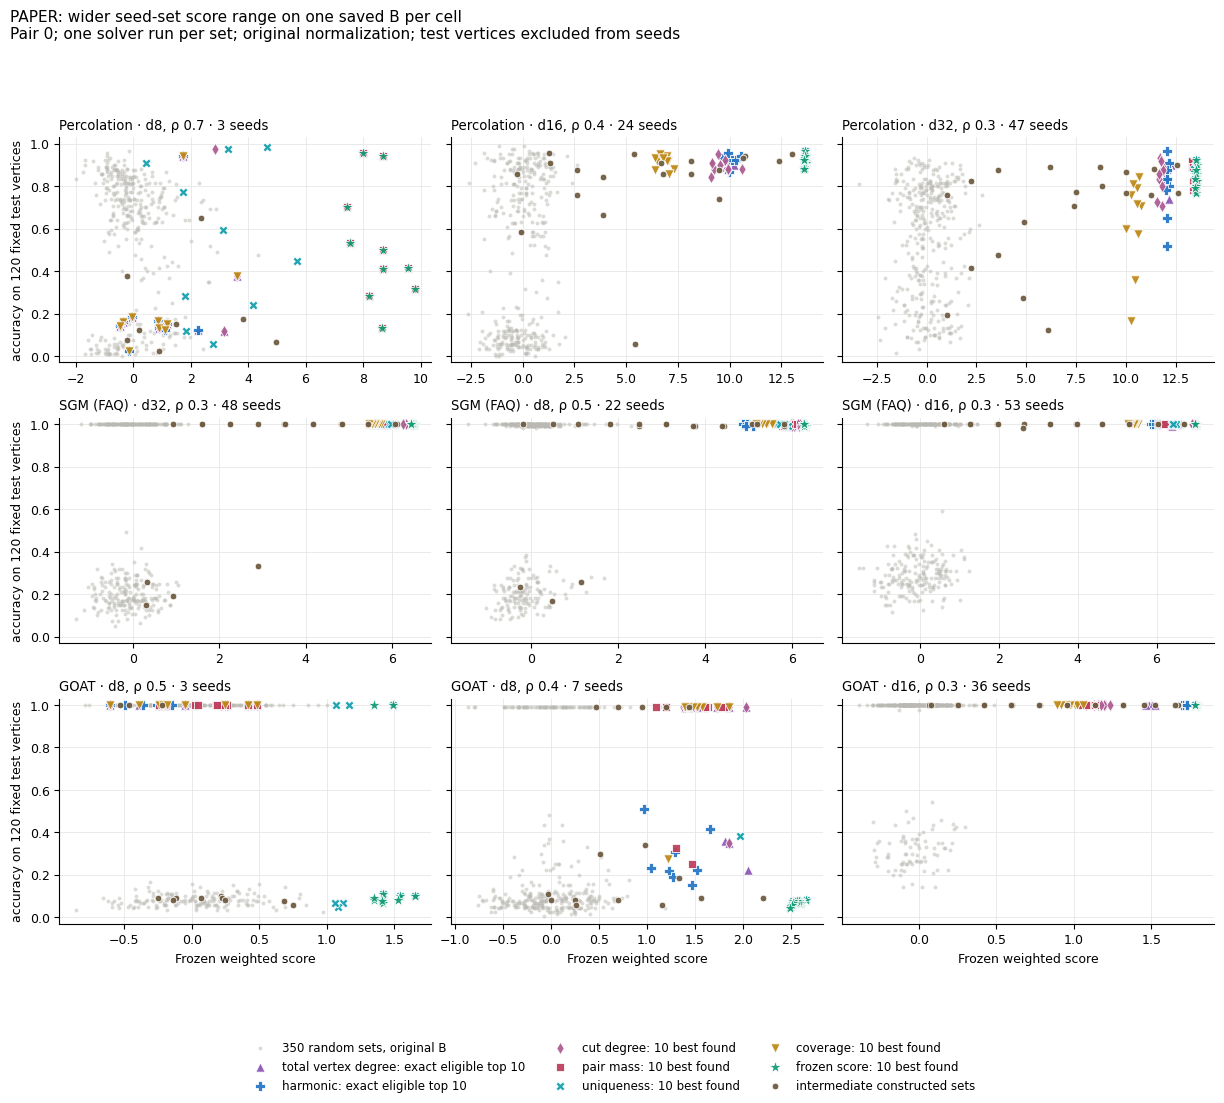

In [3]:
from selection_rule_comparison import landscape_extremes as LE
LE = importlib.reload(LE)

RUN_WIDE_COLLECTION = True
if RUN_WIDE_COLLECTION:
    LE.run_all(models=L.MODELS, jobs=3, blas_threads=3)
wide = LE.read()
for model in L.MODELS:
    LE.plot_single_b(sets, wide, model, save=True)
    plt.show()


### The same with degree alone

`x='z_degree'` plots the seeds' degree (z-score against the pool) instead of the frozen score. Where the two figures look alike, the score adds little to degree.

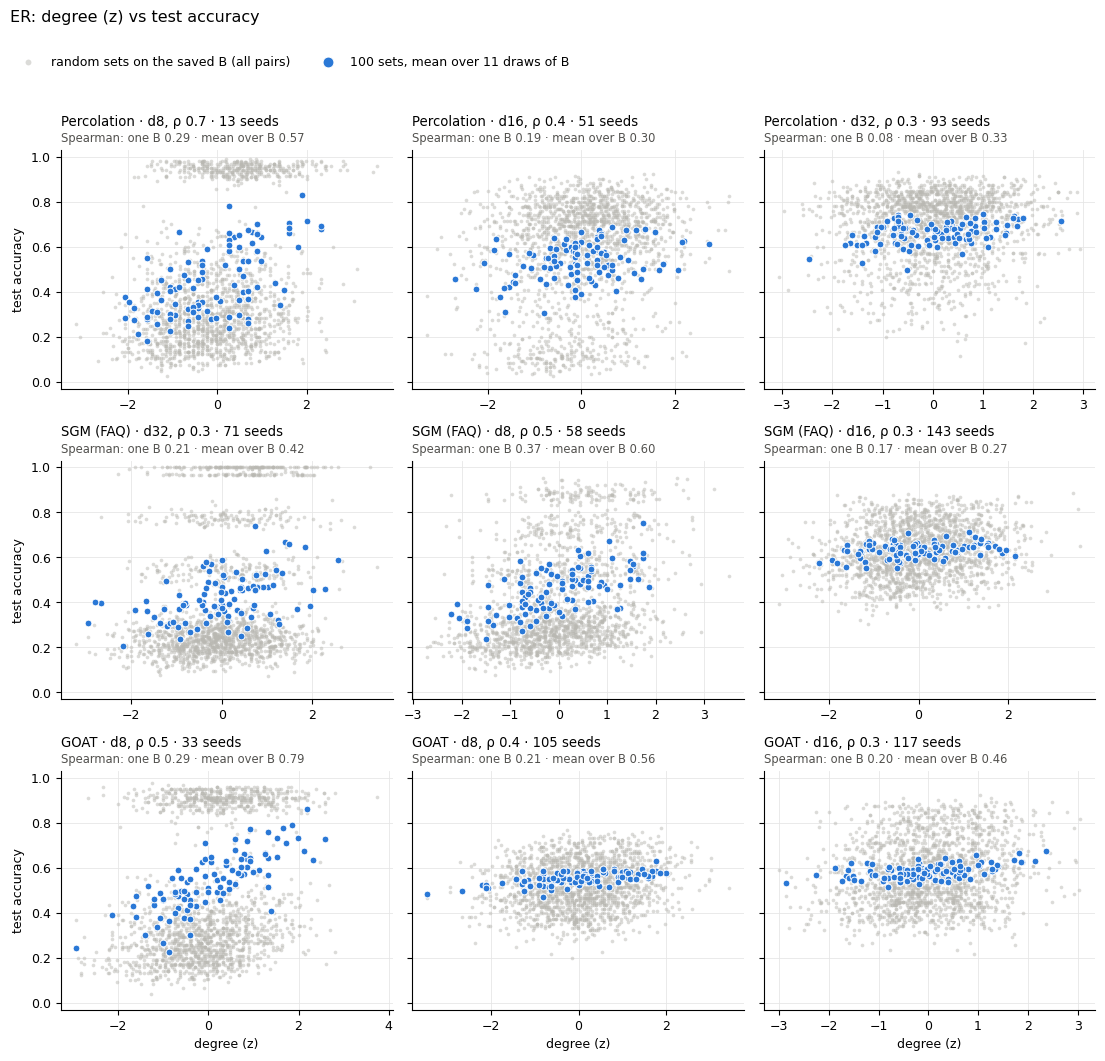

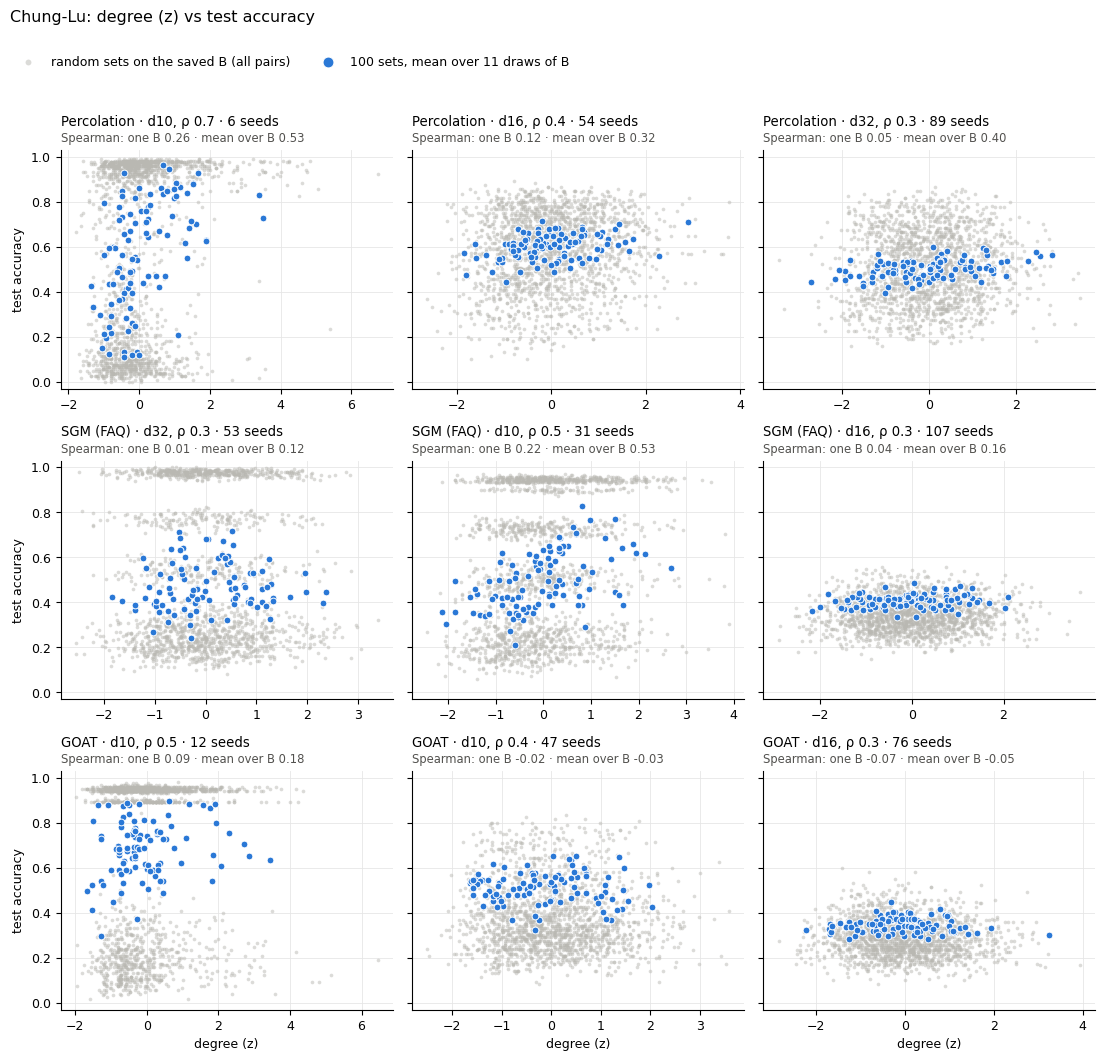

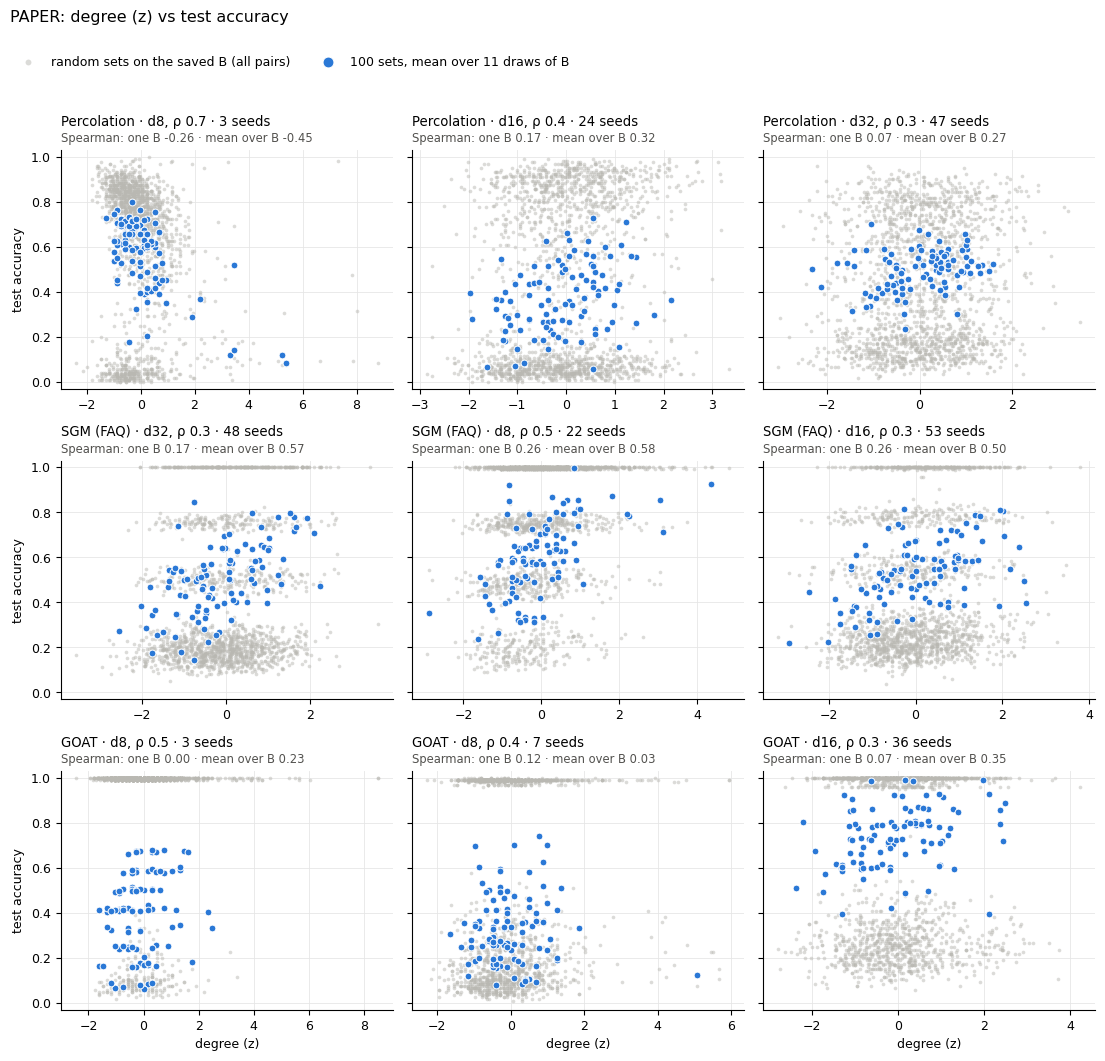

In [5]:
for model in L.MODELS:
    L.plot_score_vs_accuracy(sets, quality, model, x='z_degree')
    plt.show()

### The numbers

Per cell, over random sets:
- **mean, SD:** test accuracy on the saved B; **part-way share:** single runs ending between 0.2 and 0.8.
- **score, one B / degree, one B:** Spearman with accuracy on the saved B, within pair, averaged over the five pairs.
- **score, mean over B / degree, mean over B:** Spearman with the redrawn sets' mean over 11 draws of B (pair 0).
- **score, success over B:** Spearman with the share of draws where the set reaches 0.5: ranking by how reliably a set works gives nearly the same order as ranking by its mean.

In [6]:
ranking = L.ranking_table(sets, quality)
display(L.show(ranking))

pairs  random sets  mean    SD  part-way share  score, one B  degree, one B  score, mean over B  degree, mean over B  score, success over B
model    algorithm   mean degree ρ   level budget                                                                                                                                             
ER       Percolation 8           0.7 0.5   13          5         1750  0.44  0.30            0.56          0.38           0.29                0.74                 0.57                   0.63
                     16          0.4 0.5   51          5         1750  0.58  0.22            0.77          0.20           0.19                0.44                 0.30                   0.43
                     32          0.3 0.5   93          5         1750  0.69  0.15            0.76          0.06           0.08                0.31                 0.33                   0.20
         SGM (FAQ)   8           0.5 0.5   58          5         1750  0.41  0.22            0.68          0.36           0.37                0.60                 0.60                   0.53
                     16          0.3 0.5   143         5         1750  0.63  0.11            0.89          0.16           0.17                0.18                 0.27                   0.12
                     32          0.3 0.5   71          5         1750  0.40  0.28            0.58          0.19           0.21                0.39                 0.42                   0.33
         GOAT        8           0.4 0.5   105         5         1750  0.52  0.10            1.00          0.18           0.21                0.44                 0.56                   0.43
                                 0.5 0.5   33          5         1750  0.47  0.30            0.56          0.29           0.29                0.77                 0.79                   0.71
                     16          0.3 0.5   117         5         1750  0.58  0.15            0.91          0.16           0.20                0.37                 0.46                   0.38
Chung-Lu Percolation 10          0.7 0.5   6           5         1750  0.58  0.39            0.18          0.42           0.26                0.80                 0.53                   0.79
                     16          0.4 0.5   54          5         1750  0.58  0.17            0.92          0.14           0.12                0.43                 0.32                   0.44
                     32          0.3 0.5   89          5         1750  0.51  0.15            0.97          0.10           0.05                0.44                 0.40                   0.31
         SGM (FAQ)   10          0.5 0.5   31          5         1750  0.57  0.30            0.36          0.31           0.22                0.53                 0.53                   0.49
                     16          0.3 0.5   107         5         1750  0.35  0.07            0.99          0.08           0.04                0.04                 0.16                  -0.08
                     32          0.3 0.5   53          5         1750  0.53  0.32            0.48          0.06           0.01                0.15                 0.12                   0.13
         GOAT        10          0.4 0.5   47          5         1750  0.38  0.15            0.93          0.13          -0.02                0.27                -0.03                   0.27
                                 0.5 0.5   12          5         1750  0.67  0.36            0.17          0.13           0.09                0.40                 0.18                   0.39
                     16          0.3 0.5   76          5         1750  0.29  0.08            0.89          0.08          -0.07                0.01                -0.05                  -0.06
PAPER    Percolation 8           0.7 0.5   3           5         1750  0.60  0.30            0.50         -0.18          -0.26               -0.35                -0.45                  -0.25
                     16          0.4 0.5

## 4. How much of a single run is the seed set?

From the 100 sets × 11 draws of B per cell, a two-way split of the variance of single runs:
- **draw of B:** how hard that draw is overall; it moves every set together and does not change which set is best;
- **seed set:** differences between sets that hold across draws, which is all a rule that sees only graph A can use;
- **rest:** which sets a particular draw happens to favour, plus solver noise.

**Seed-set share on a fixed B** is the set's share once the draw's overall difficulty is removed; its square root is the **ceiling** on any graph-A predictor's correlation with single runs. **Ranking agreement** is the mean Spearman between the same sets' accuracies on two draws.

In [7]:
variance = L.variance_table(draws)
display(L.show(variance))

sets  draws of B  share: draw of B  share: seed set  share: rest  seed-set share on a fixed B  ceiling on r  ranking agreement between draws draw means
model    algorithm   mean degree ρ   level budget                                                                                                                                                         
ER       Percolation 8           0.7 0.5   13       100          11              0.04             0.18         0.78                         0.18          0.43                             0.15  0.36-0.61
                     16          0.4 0.5   51       100          11              0.17             0.05         0.78                         0.06          0.25                             0.05  0.37-0.67
                     32          0.3 0.5   93       100          11              0.34             0.03         0.63                         0.04          0.21                             0.04  0.54-0.80
         SGM (FAQ)   8           0.5 0.5   58       100          11              0.24             0.05         0.71                         0.07          0.26                             0.11  0.24-0.72
                     16          0.3 0.5   143      100          11              0.59             0.01         0.41                         0.01          0.12                            -0.00  0.46-0.84
                     32          0.3 0.5   71       100          11              0.28             0.04         0.68                         0.05          0.22                             0.06  0.25-0.74
         GOAT        8           0.4 0.5   105      100          11              0.53             0.03         0.44                         0.07          0.26                             0.06  0.44-0.69
                                 0.5 0.5   33       100          11              0.28             0.09         0.63                         0.13          0.36                             0.13  0.22-0.77
                     16          0.3 0.5   117      100          11              0.65             0.00         0.35                         0.00          0.05                            -0.01  0.41-0.84
Chung-Lu Percolation 10          0.7 0.5   6        100          11              0.01             0.29         0.70                         0.29          0.54                             0.23  0.49-0.71
                     16          0.4 0.5   54       100          11              0.12             0.04         0.84                         0.05          0.22                             0.04  0.54-0.72
                     32          0.3 0.5   89       100          11              0.33             0.02         0.65                         0.03          0.17                             0.04  0.36-0.68
         SGM (FAQ)   10          0.5 0.5   31       100          11              0.17             0.07         0.76                         0.08          0.29                             0.09  0.35-0.82
                     16          0.3 0.5   107      100          11              0.30             0.04         0.66                         0.05          0.23                             0.05  0.33-0.51
                     32          0.3 0.5   53       100          11              0.34             0.04         0.62                         0.06          0.24                             0.03  0.29-0.80
         GOAT        10          0.4 0.5   47       100          11              0.19             0.07         0.74                         0.09          0.30                             0.09  0.32-0.59
                                 0.5 0.5   12       100          11              0.12             0.04         0.83                         0.05          0.22                             0.03  0.51-0.89
                     16          0.3 0.5   76       100          11              0.26             0.05         0.69                         0.07          0.26                             0.06  0

## 5. Every seed set by design

All seed sets on the saved B, one point per set and pair: random sets (grey), degree-tilted sets (blue, light to dark for γ = −1 to 3), the pool's sets at quantiles of the frozen score (pink), round 1's rules (orange and dark shapes) and the best-of screens (aqua). The rules sit far to the right of every random set on the score axis: they are built, not sampled.

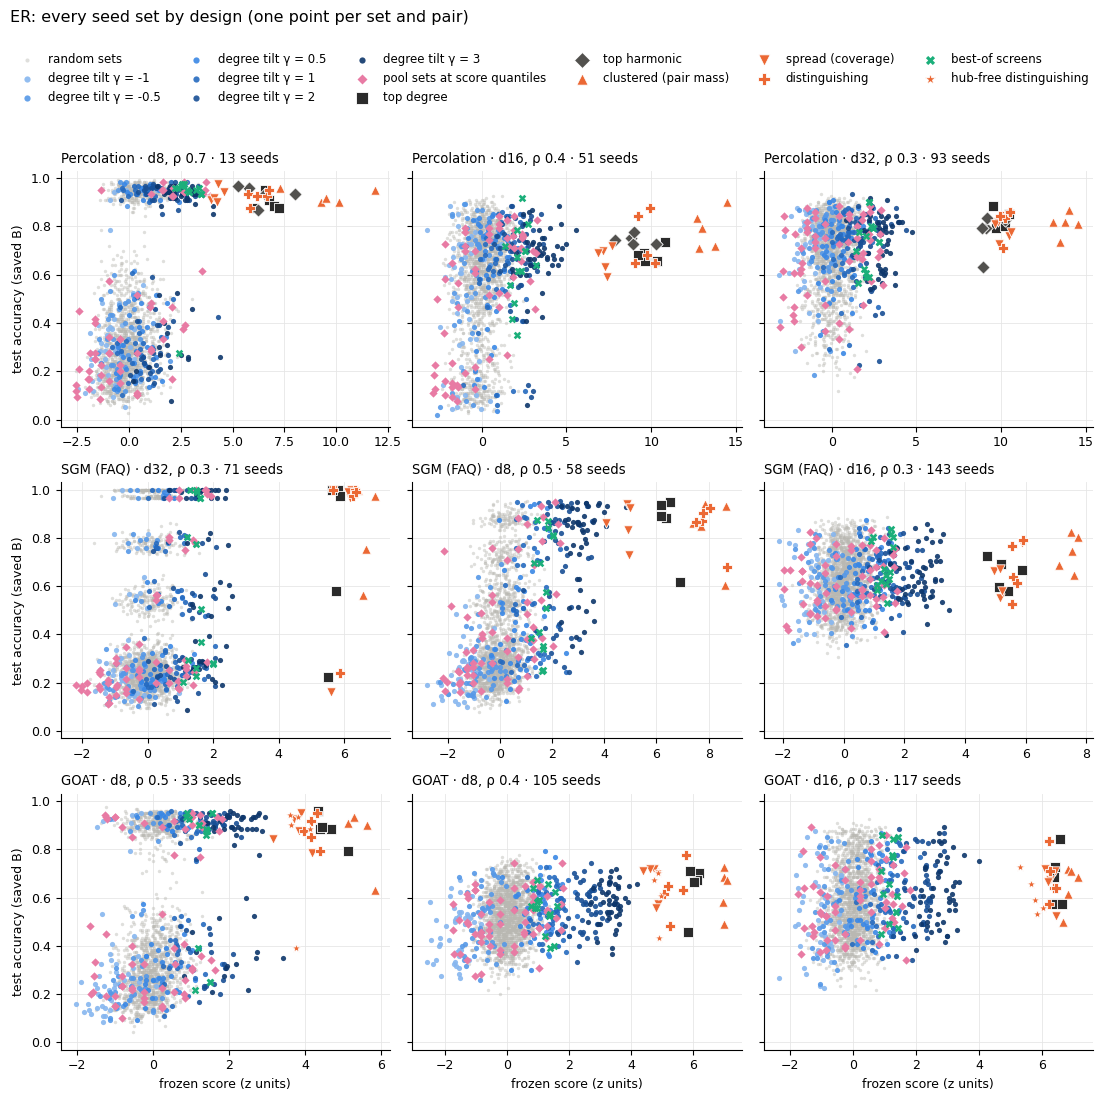

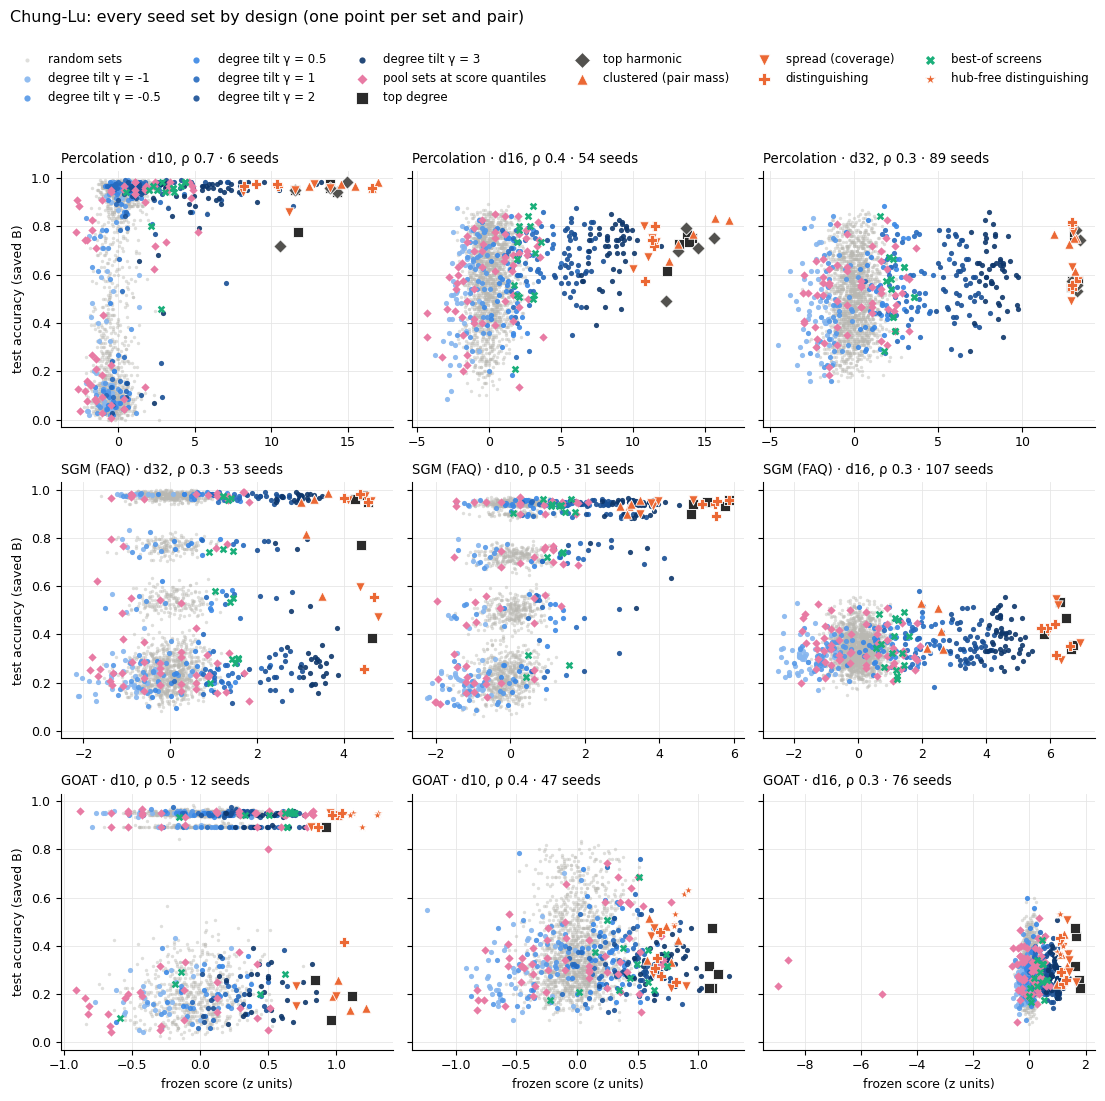

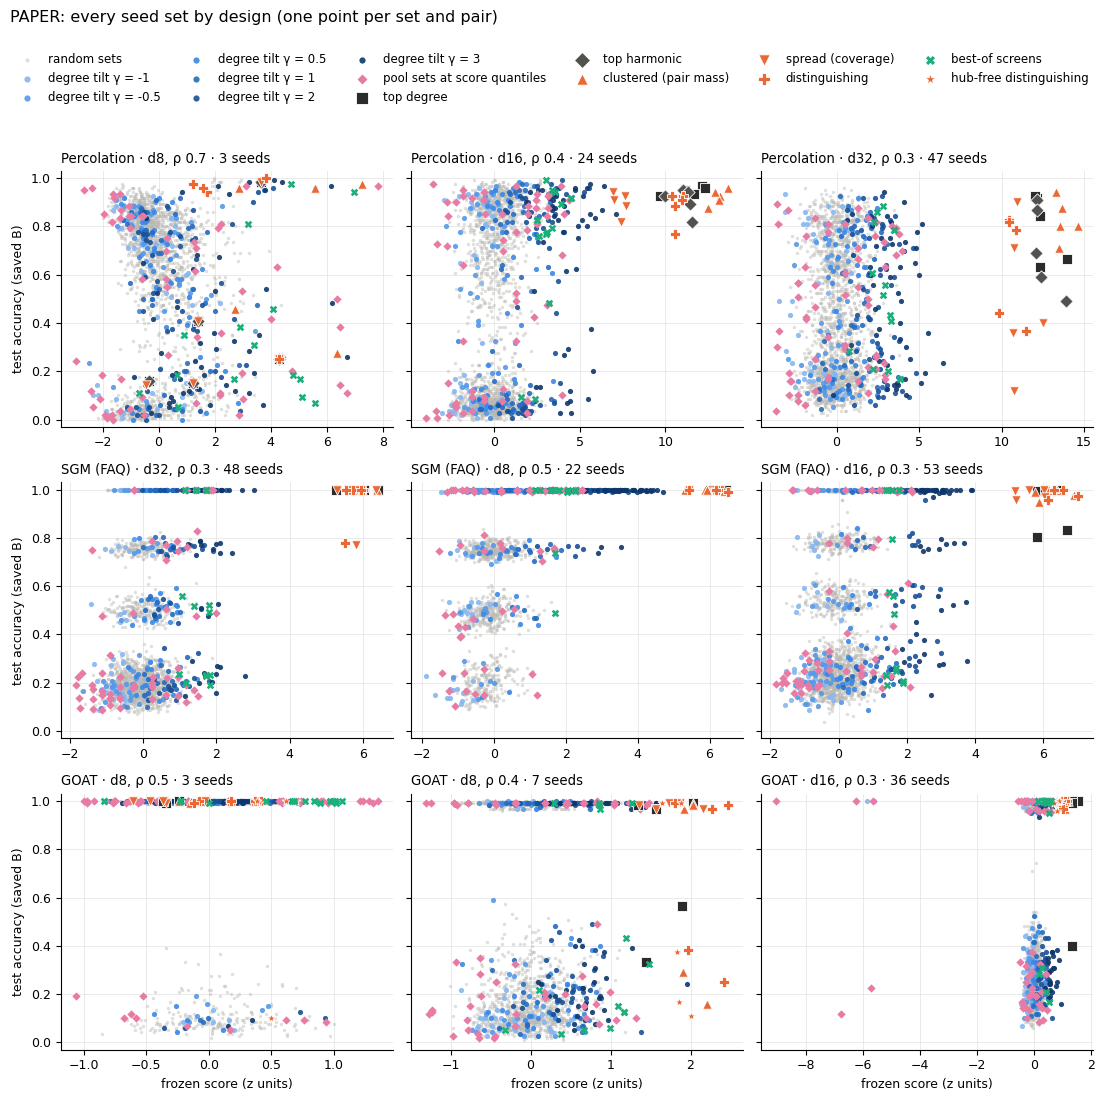

In [8]:
for model in L.MODELS:
    L.plot_designed_sets(sets, model)
    plt.show()

## 6. Screening random sets vs building sets

Test accuracy on the saved B, averaged over pairs, for each way of choosing seeds. **Best of ~18,650 by score** is the pool's top set by the frozen score (the quantile pick at 1). **Best rule** is picked per cell, so it is slightly optimistic. In the figure, grey lines are cells and blue is the median over cells: screening random sets, however many, stays well below building sets with a rule.

random sets  best of 100 by score  best of 1,000 by score  best of 1,000 by degree  best of ~18,650 by score  degree tilt γ = 3  round 1's rules (mean)  best rule               which rule
model    algorithm   mean degree ρ   level budget                                                                                                                                                                                             
ER       Percolation 8           0.7 0.5   13             0.44                  0.96                    0.94                     0.82                      0.88               0.72                    0.92       0.93             top_harmonic
                     16          0.4 0.5   51             0.58                  0.57                    0.68                     0.68                      0.65               0.67                    0.72       0.79                clustered
                     32          0.3 0.5   93             0.69                  0.71                    0.76                     0.70                      0.71               0.74                    0.80       0.83               top_degree
         SGM (FAQ)   8           0.5 0.5   58             0.41                  0.54                    0.57                     0.62                      0.70               0.77                    0.85       0.86                   spread
                     16          0.3 0.5   143            0.63                  0.66                    0.71                     0.70                      0.65               0.64                    0.68       0.74                clustered
                     32          0.3 0.5   71             0.40                  0.66                    0.53                     0.60                      0.85               0.62                    0.82       0.86                clustered
         GOAT        8           0.4 0.5   105            0.52                  0.56                    0.55                     0.55                      0.59               0.58                    0.64       0.66                   spread
                                 0.5 0.5   33             0.47                  0.78                    0.77                     0.67                      0.68               0.75                    0.86       0.88               top_degree
                     16          0.3 0.5   117            0.58                  0.69                    0.65                     0.65                      0.61               0.63                    0.66       0.68           distinguishing
Chung-Lu Percolation 10          0.7 0.5   6              0.58                  0.93                    0.97                     0.86                      0.92               0.91                    0.94       0.97                clustered
                     16          0.4 0.5   54             0.58                  0.66                    0.66                     0.62                      0.66               0.69                    0.72       0.76                clustered
                     32          0.3 0.5   89             0.51                  0.54                    0.52                     0.55                      0.56               0.61                    0.66       0.72                clustered
         SGM (FAQ)   10          0.5 0.5   31             0.57                  0.85                    0.76                     0.67                      0.89               0.91                    0.94       0.94                   spread
                     16          0.3 0.5   107            0.35                  0.34                    0.34                     0.37                      0.33               0.39                    0.42       0.43                clustered
                     32          0.3 0.5   53             0.53                  0.66                    0.53                     0.65                      0.66               0.60                    0.80       0.85              

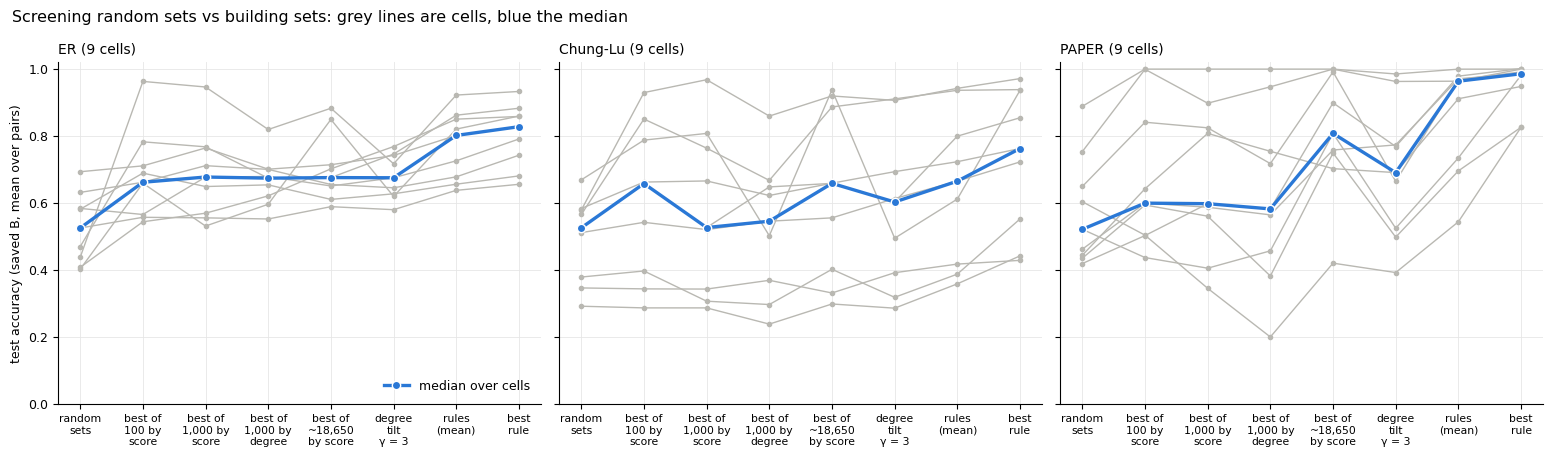

In [9]:
construct = L.construct_table(sets)
display(L.show(construct))
L.plot_construct(construct)
plt.show()

## 7. Degree tilt and feature quantiles

**Degree tilt:** gain over random sets of the same pair for sets drawn with probability ∝ degree^γ; below 0 the sets favour low-degree vertices, above 0 high-degree ones.

**Quantiles:** sets from the pool picked at quantiles of one feature, lowest (left) to highest (right), as gain over random sets. A feature that matters climbs from left to right. Each point is one set per pair averaged over five pairs, so single points are noisy; look at the trend.

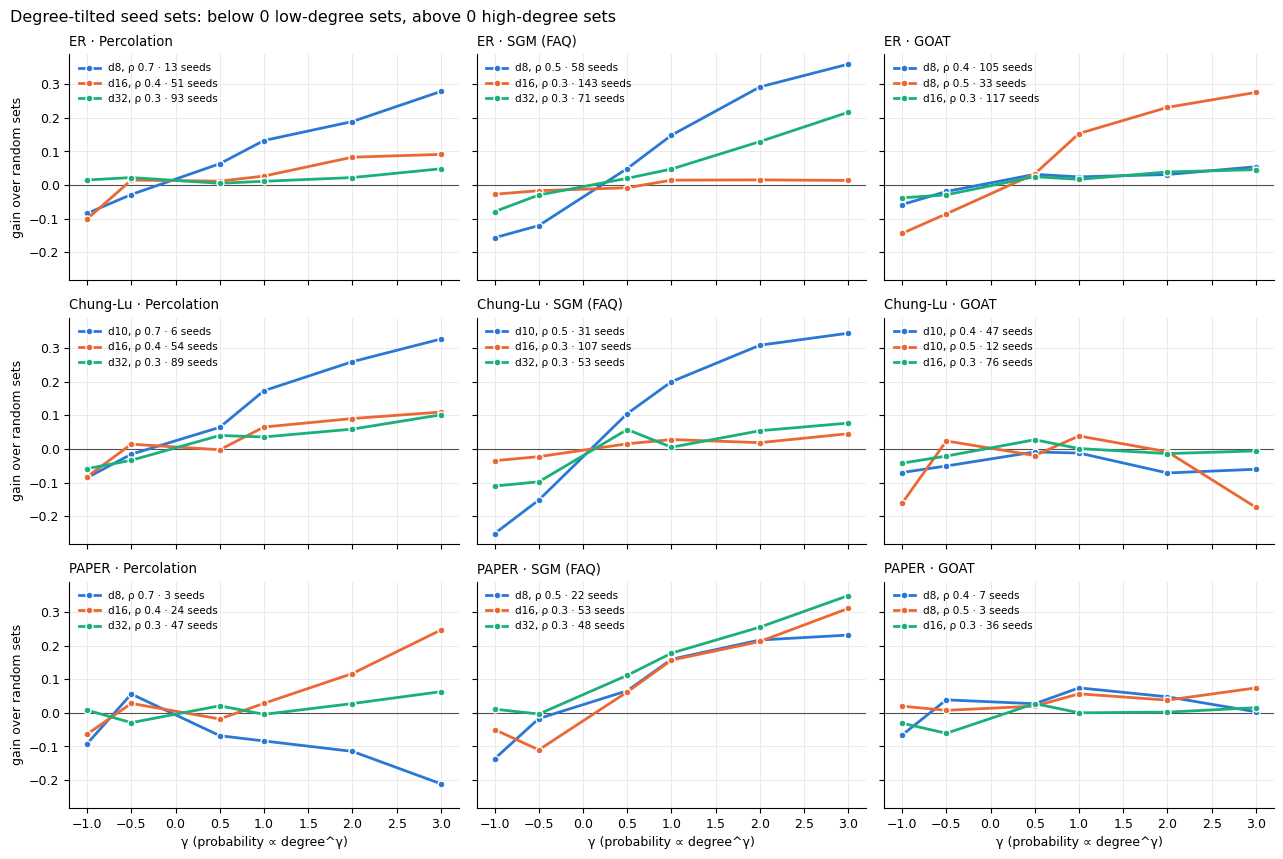

In [10]:
L.plot_tilt(sets)
plt.show()

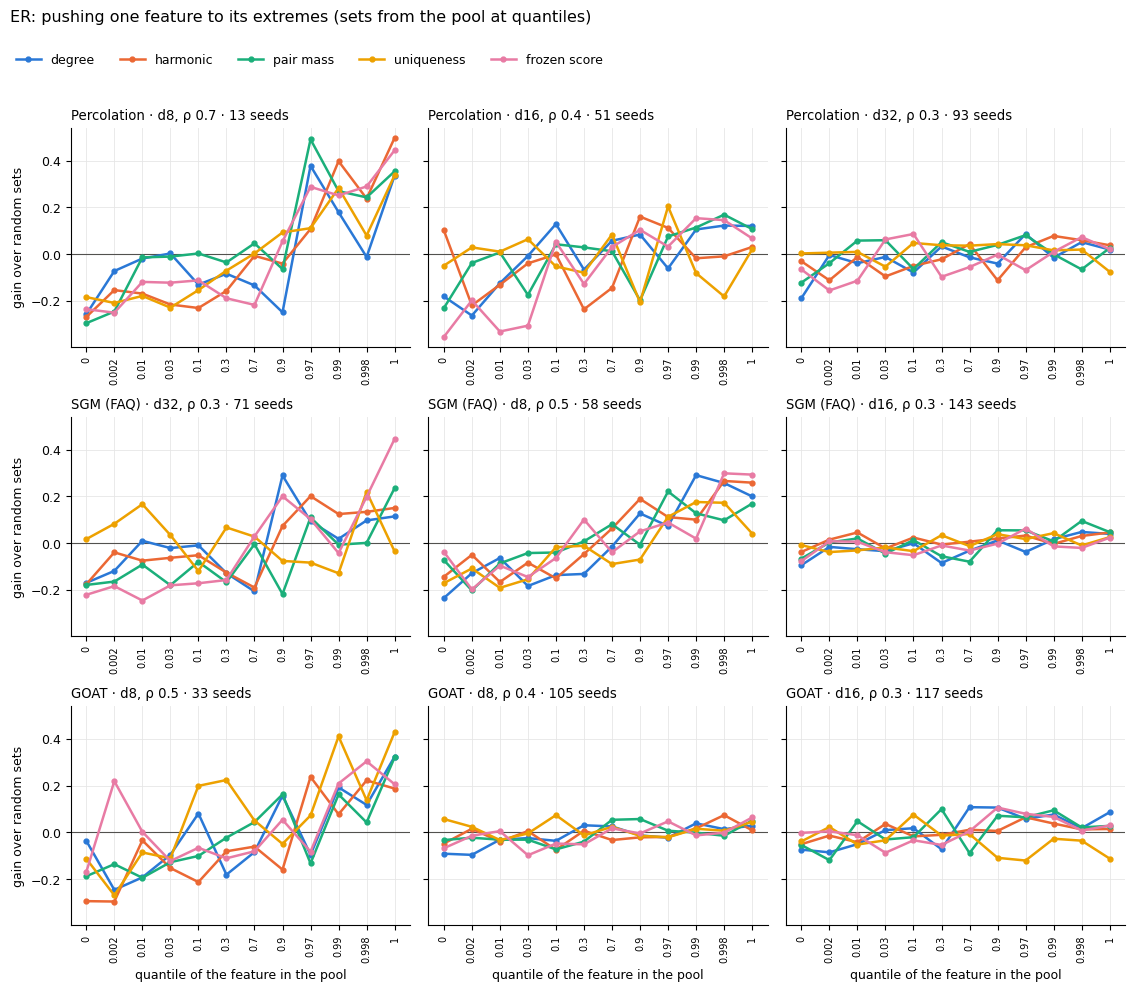

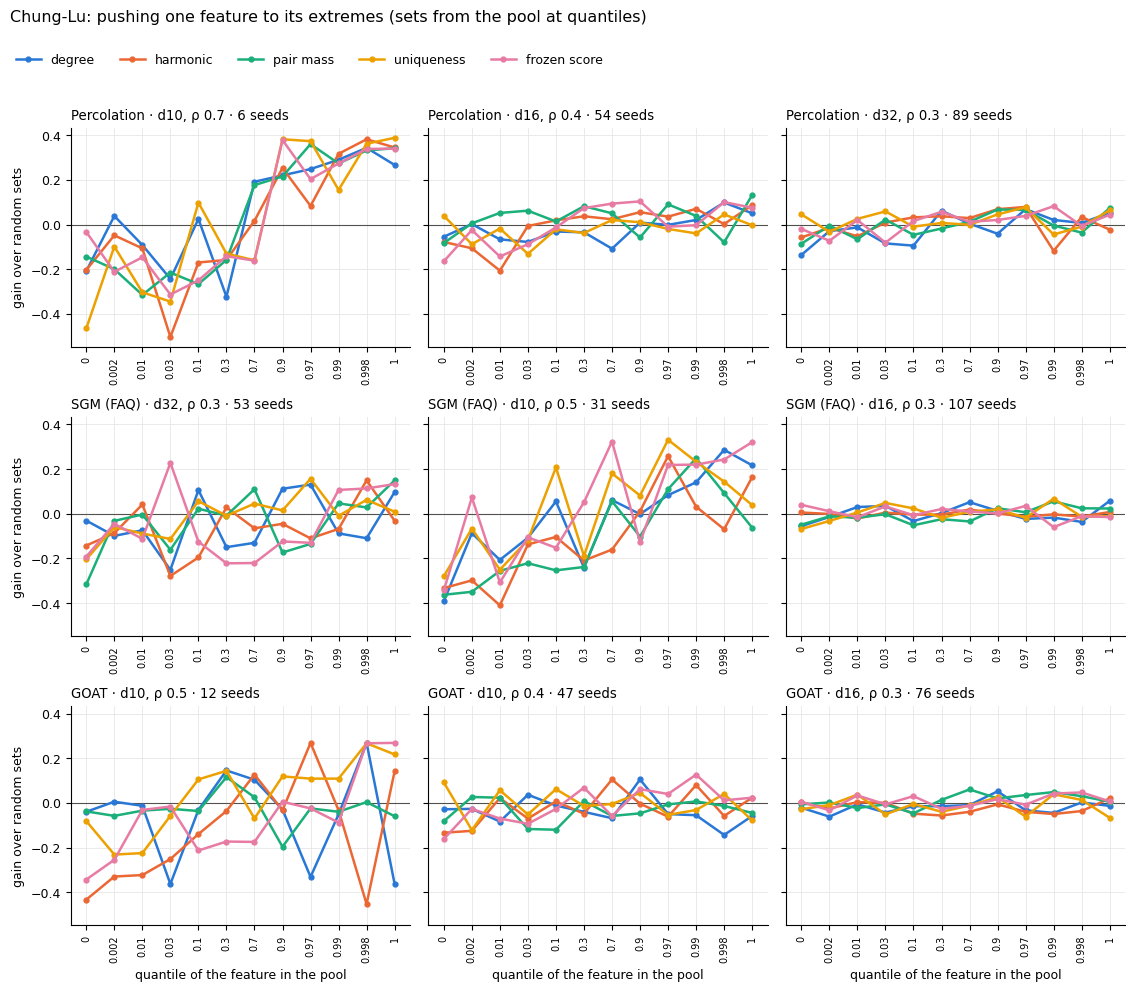

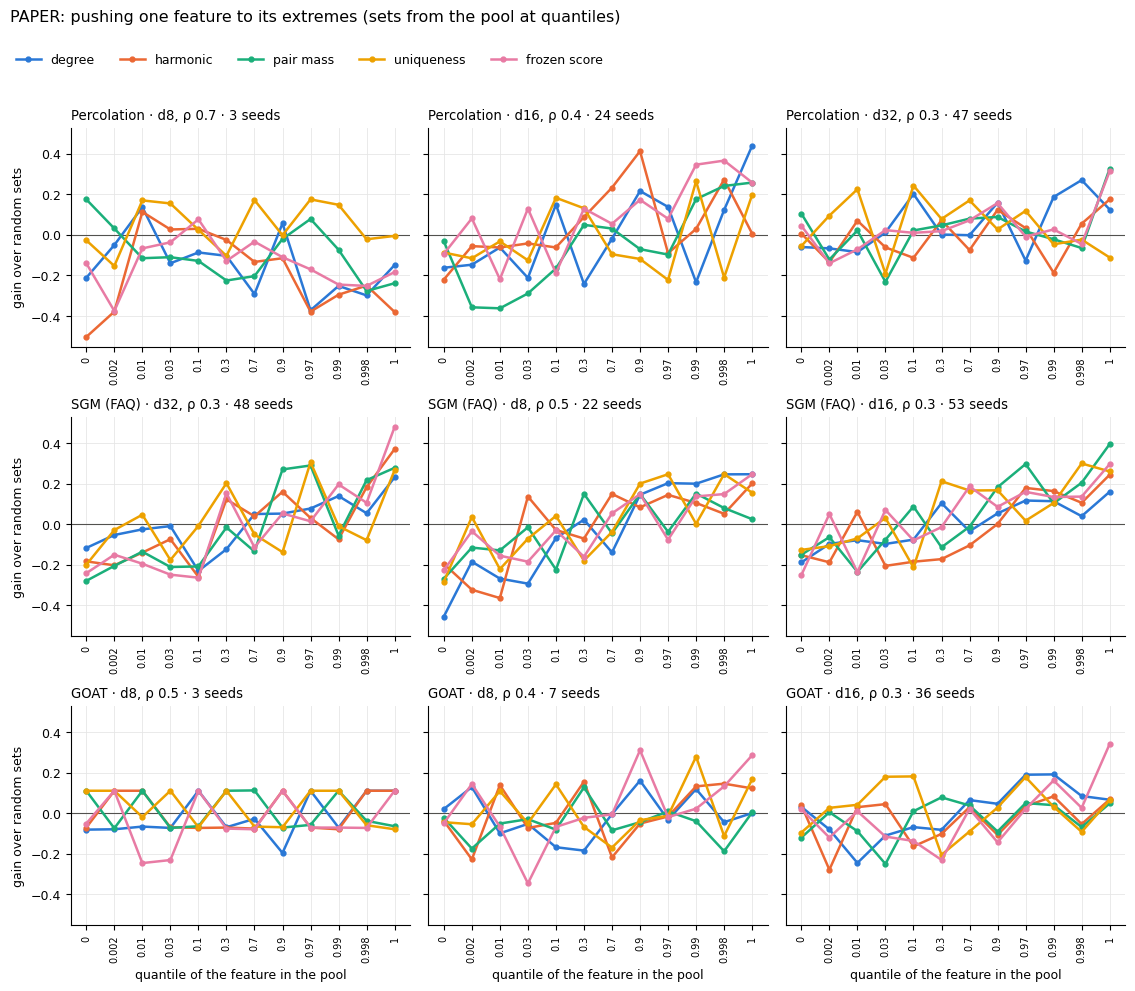

In [11]:
for model in L.MODELS:
    L.plot_quantiles(sets, model)
    plt.show()

## 8. Which features track the match ratio?

Spearman correlation of each feature with test accuracy over random sets on the saved B (within pair, averaged over pairs), one column per cell. The top rows are graph-A features a rule can compute; the bottom rows are graph-B features no rule can see, such as how many of the seeds' edges to non-seeds survive in B. The core z-scores are left out: within a pair they rank sets exactly as the fixed-pair degree, harmonic, pair mass and uniqueness rows do.

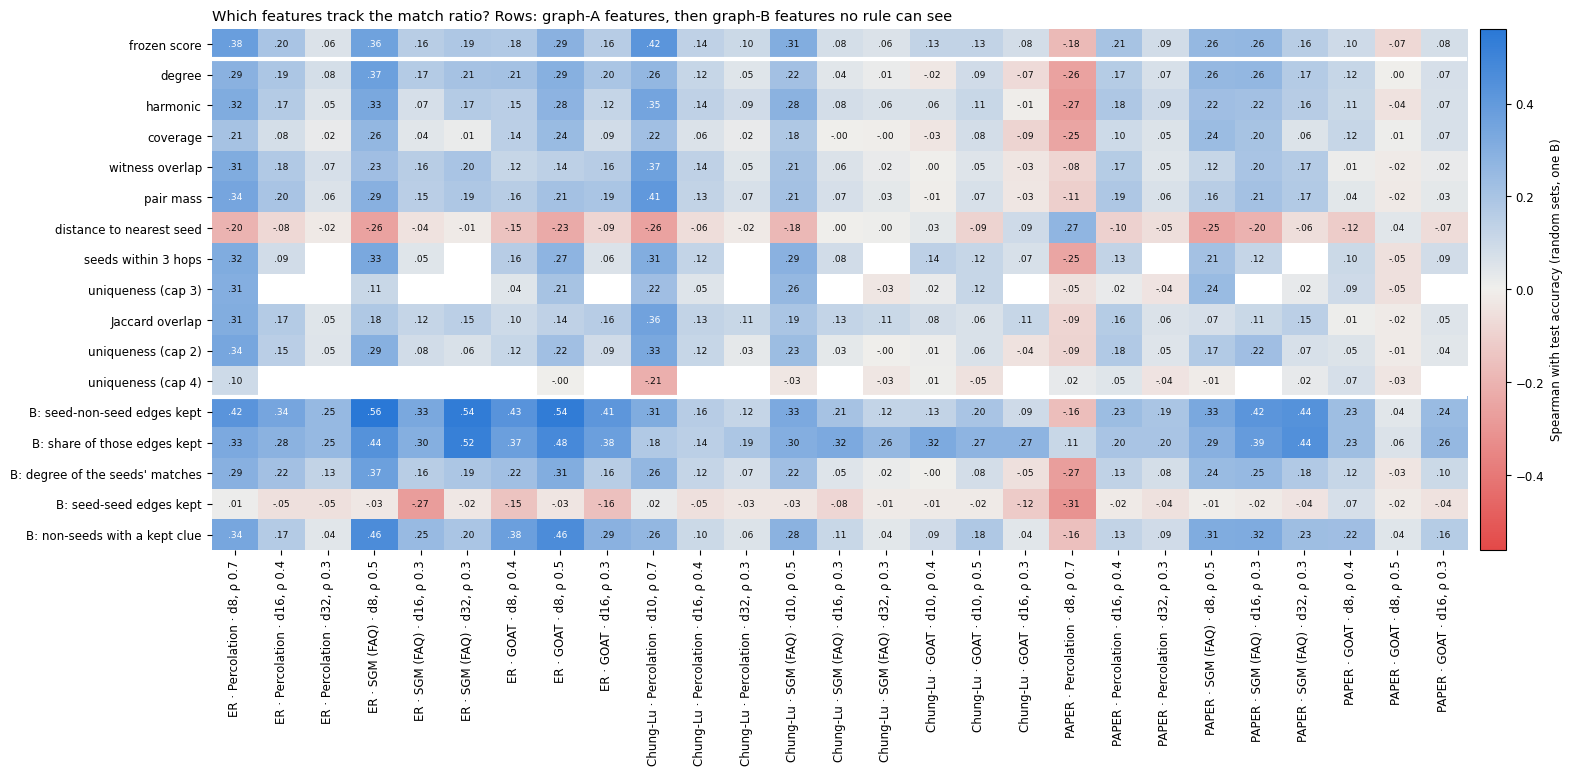

In [12]:
features = L.feature_table(sets)
L.plot_feature_heatmap(features)
plt.show()

## 9. Budget level: 20%, 50% and 80%

**Landscape (ER):** the same nine cells at the budgets where random sets average 20%, 50% and 80% (one pair at 20% and 80%, five at 50%).

In [13]:
display(L.show(L.level_table(sets), kind=None))

pairs  random mean  part-way share  score, one B  best rule gain  best of 1,000 gain
model algorithm   mean degree ρ   level budget                                                                                      
ER    Percolation 8           0.7 0.2   9           1         0.19            0.33          0.32            0.75               -0.11
                                  0.5   13          5         0.44            0.56          0.38            0.49                0.51
                                  0.8   17          1         0.75            0.33          0.28            0.21                0.16
                  16          0.4 0.2   41          1         0.25            0.39          0.16            0.57                0.48
                                  0.5   51          5         0.58            0.77          0.20            0.21                0.09
                                  0.8   77          1         0.86            0.11          0.04            0.03               -0.03
                  32          0.3 0.2   67          1         0.18            0.32          0.16            0.36               -0.01
                                  0.5   93          5         0.69            0.76          0.06            0.13                0.07
                                  0.8   121         1         0.87            0.07          0.06            0.06               -0.03
      SGM (FAQ)   8           0.5 0.2   43          1         0.18            0.34          0.26            0.66               -0.01
                                  0.5   58          5         0.41            0.68          0.36            0.45                0.16
                                  0.8   81          1         0.89            0.00         -0.03           -0.03               -0.01
                  16          0.3 0.2   93          1         0.22            0.67          0.18            0.11               -0.02
                                  0.5   143         5         0.63            0.89          0.16            0.11                0.08
                                  0.8   220         1         0.86            0.05         -0.08           -0.01               -0.03
                  32          0.3 0.2   62          1         0.18            0.30          0.15            0.59                0.02
                                  0.5   71          5         0.40            0.58          0.19            0.46                0.13
                                  0.8   82          1         0.95            0.08          0.10            0.05                0.05
      GOAT        8           0.4 0.2   54          1         0.18            0.37          0.06            0.21                0.03
                                  0.5   105         5         0.52            1.00          0.18            0.13                0.03
                                  0.8   272         1         0.87            0.00         -0.05           -0.00               -0.01
                              0.5 0.2   27          1         0.43            0.58          0.28            0.43                0.06
                                  0.5   33          5         0.47            0.56          0.29            0.41                0.30
                                  0.8   44          1         0.89            0.01         -0.12           -0.00               -0.03
                  16          0.3 0.2   75          1         0.20            0.49          0.13            0.15                0.06
                                  0.5   117         5         0.58            0.91          0.16            0.10                0.07
                                  0.8   190         1         0.86            0.03         -0.03           -0.02                0.03

**Regime map stage 2 (all three models, every cell with a 20–80% rise):** the gain of the best of round 1's rules over random sets at the three budgets, median over cells (dots) and middle half (bars). The best rule is picked per cell, so the gains are slightly optimistic; the table also shows the best of 1,000 random sets by the frozen score.

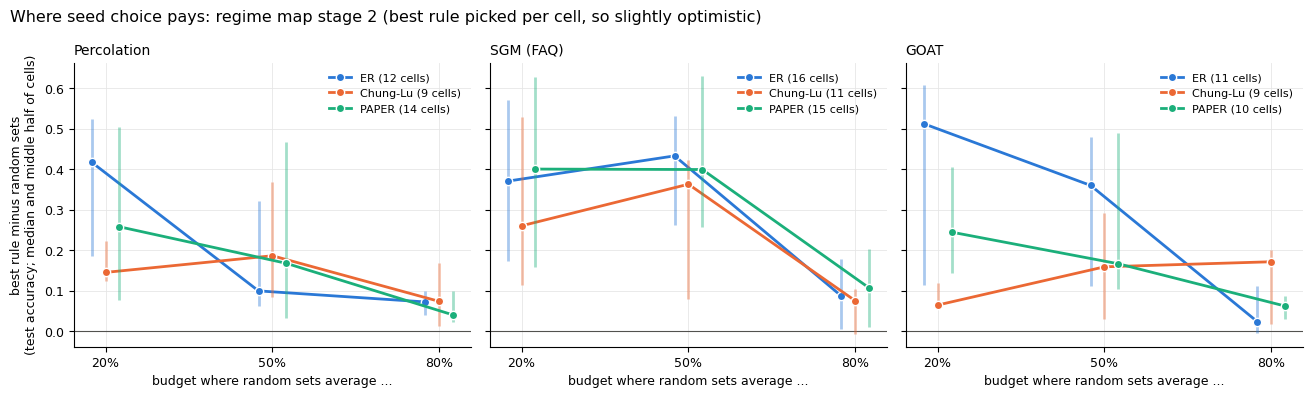

cells  best rule gain, 20%  best rule gain, 50%  best rule gain, 80%  best of 1,000 gain, 20%  best of 1,000 gain, 50%  best of 1,000 gain, 80%
model    algorithm                                                                                                                                                   
ER       Percolation     12                 0.42                 0.10                 0.07                     0.10                     0.04                     0.03
         SGM (FAQ)       16                 0.37                 0.43                 0.09                     0.03                     0.18                     0.06
         GOAT            11                 0.51                 0.36                 0.02                     0.03                     0.16                     0.00
Chung-Lu Percolation      9                 0.15                 0.19                 0.07                     0.05                     0.01                     0.02
         SGM (FAQ)       11                 0.26                 0.36                 0.08                    -0.00                     0.08                     0.02
         GOAT             9                 0.06                 0.16                 0.17                     0.01                     0.02                     0.04
PAPER    Percolation     14                 0.26                 0.17                 0.04                     0.04                     0.05                     0.04
         SGM (FAQ)       15                 0.40                 0.40                 0.11                     0.03                     0.19                     0.08
         GOAT            10                 0.24                 0.17                 0.06                     0.02                    -0.07                    -0.01

In [14]:
stage2 = L.stage2_levels()
L.plot_stage2_levels(stage2)
plt.show()
display(L.stage2_summary(stage2))

## 10. The hard cell: ER, mean degree 16, ρ 0.2

Random sets never reach 50% in the regime map's range here, so the cell ran at 300 seeds, where they average about 0.35.

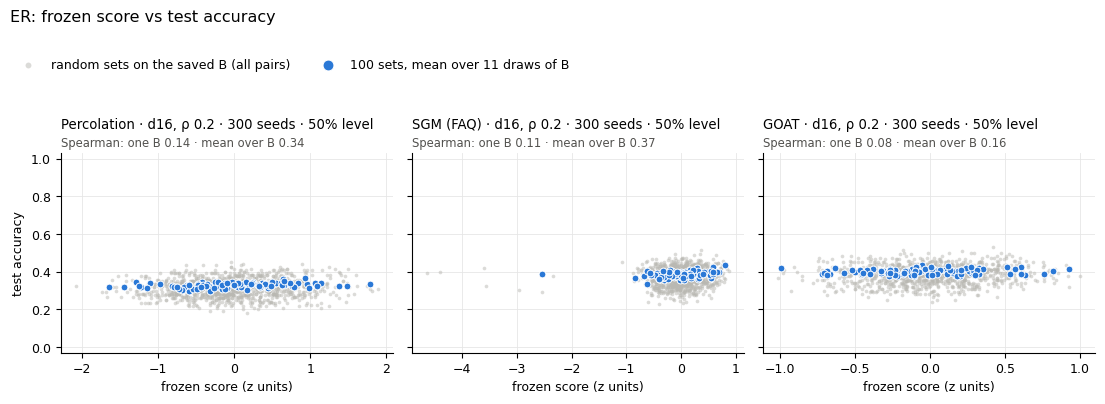

pairs  random sets  mean    SD  part-way share  score, one B  degree, one B  score, mean over B  degree, mean over B  score, success over B
model algorithm   mean degree ρ   level budget                                                                                                                                             
ER    Percolation 16          0.2 0.5   300         3         1050  0.32  0.05             1.0          0.14           0.11                0.34                 0.43                   0.14
      SGM (FAQ)   16          0.2 0.5   300         3         1050  0.37  0.05             1.0          0.11           0.13                0.37                 0.42                   0.10
      GOAT        16          0.2 0.5   300         3         1050  0.39  0.05             1.0          0.08           0.12                0.16                 0.42                  -0.10

sets  draws of B  share: draw of B  share: seed set  share: rest  seed-set share on a fixed B  ceiling on r  ranking agreement between draws draw means
model algorithm   mean degree ρ   level budget                                                                                                                                                         
ER    Percolation 16          0.2 0.5   300      100          11              0.48             0.01         0.51                         0.02          0.13                             0.01  0.28-0.39
      SGM (FAQ)   16          0.2 0.5   300      100          11              0.55             0.02         0.43                         0.04          0.20                             0.03  0.33-0.47
      GOAT        16          0.2 0.5   300      100          11              0.58             0.01         0.41                         0.02          0.15                             0.02  0.35-0.49

random sets  best of 100 by score  best of 1,000 by score  best of 1,000 by degree  best of ~18,650 by score  degree tilt γ = 3  round 1's rules (mean)  best rule  which rule
model algorithm   mean degree ρ   level budget                                                                                                                                                                                
ER    Percolation 16          0.2 0.5   300            0.32                  0.32                    0.32                     0.29                      0.34               0.33                    0.36       0.37  top_degree
      SGM (FAQ)   16          0.2 0.5   300            0.37                  0.35                    0.40                     0.38                      0.39               0.38                    0.41       0.43   clustered
      GOAT        16          0.2 0.5   300            0.39                  0.36                    0.42                     0.42                      0.41               0.39                    0.41       0.44   clustered

In [15]:
L.plot_score_vs_accuracy(sets, quality, 'sparse_er', kind='extra')
plt.show()
display(L.show(ranking, kind='extra'))
display(L.show(variance, kind='extra'))
display(L.show(L.construct_table(sets, kind='extra'), kind='extra'))

## 11. First-step accuracy as a cheap label (Direction 1b)

Over random sets, within pair: Spearman between the accuracy after the first Hungarian step and the final accuracy, compared with the frozen score's correlation with each. First-step accuracy needs B, so it is a cheap label for training and evaluation, not a selection rule.

In [16]:
display(L.show(L.first_step_table(sets)))

first-step mean  final mean  first step vs final  score vs final  score vs first step
model    algorithm mean degree ρ   level budget                                                                                       
ER       SGM (FAQ) 8           0.5 0.5   58                 0.11        0.41                 0.71            0.36                 0.41
                   16          0.3 0.5   143                0.25        0.63                 0.47            0.16                 0.24
                   32          0.3 0.5   71                 0.15        0.40                 0.73            0.19                 0.17
         GOAT      8           0.4 0.5   105                0.16        0.52                 0.38            0.18                 0.25
                               0.5 0.5   33                 0.06        0.47                 0.41            0.29                 0.31
                   16          0.3 0.5   117                0.19        0.58                 0.43            0.16                 0.24
Chung-Lu SGM (FAQ) 10          0.5 0.5   31                 0.08        0.57                 0.66            0.31                 0.30
                   16          0.3 0.5   107                0.18        0.35                 0.59            0.08                 0.05
                   32          0.3 0.5   53                 0.13        0.53                 0.65            0.06                 0.09
         GOAT      10          0.4 0.5   47                 0.09        0.38                 0.43            0.13                 0.10
                               0.5 0.5   12                 0.04        0.67                 0.35            0.13                 0.22
                   16          0.3 0.5   76                 0.12        0.29                 0.44            0.08                 0.06
PAPER    SGM (FAQ) 8           0.5 0.5   22                 0.06        0.75                 0.61            0.26                 0.41
                   16          0.3 0.5   53                 0.11        0.46                 0.67            0.26                 0.38
                   32          0.3 0.5   48                 0.12        0.42                 0.75            0.16                 0.20
         GOAT      8           0.4 0.5   7                  0.02        0.52                 0.29            0.10                 0.13
                               0.5 0.5   3                  0.02        0.89                 0.10           -0.07                 0.06
                   16          0.3 0.5   36                 0.07        0.65                 0.39            0.08                 0.15

## 12. GOAT's regulariser

The 100 redrawn sets of pair 0 with GOAT's regulariser at half, the usual value (100 for ER, 300 for Chung–Lu and PAPER) and double: mean test accuracy, and how well the ranking of the sets at the usual value carries over.

In [17]:
display(L.show(L.regularizer_table(sets), kind=None))

sets  regulariser  mean at 0.5x  mean at 1x  mean at 2x  ranking 0.5x vs 1x  ranking 2x vs 1x
model    algorithm mean degree ρ   level budget                                                                                               
ER       GOAT      8           0.4 0.5   105      100        100.0          0.67        0.56        0.51                0.47              0.83
                               0.5 0.5   33       100        100.0          0.35        0.71        0.52                0.24              0.62
                   16          0.2 0.5   300      100        100.0          0.36        0.35        0.35                0.70              0.80
                               0.3 0.5   117      100        100.0          0.79        0.64        0.54                0.14              0.68
Chung-Lu GOAT      10          0.4 0.5   47       100        300.0          0.17        0.43        0.32                0.26              0.80
                               0.5 0.5   12       100        300.0          0.13        0.89        0.67                0.06              0.16
                   16          0.3 0.5   76       100        300.0          0.20        0.31        0.27                0.59              0.84
PAPER    GOAT      8           0.4 0.5   7        100        300.0          0.06        0.28        0.23                0.31              0.60
                               0.5 0.5   3        100        300.0          0.06        0.57        0.91                0.19              0.23
                   16          0.3 0.5   36       100        300.0          0.28        0.84        0.60                0.23              0.68

## Reading the results

- **Single runs are mostly luck of B.** On a fixed B the seed set explains about 5–13% of a single run's variance in most cells (at most about 30%), and rankings on two draws of B barely agree. Judge rankings against accuracy averaged over draws of B (or pairs), and compare sets within a pair.
- **The frozen score ranks set quality where seed choice matters.** Against the mean over draws of B its Spearman is 0.5–0.8 in the sparse cells, but 0.15 or less in the dense, low-ρ Chung–Lu cells and for GOAT on PAPER at 3–7 seeds.
- **Degree first.** For FAQ the score works about as well as degree alone; for percolation, and for GOAT on Chung–Lu (where high degree hurts), the other features add ranking power.
- **Build, don't screen.** The best of even ~18,650 random sets by score stays below round 1's rules, which build sets far outside the random sets' range. Next: use the score to build sets (greedy or optimised).
- **Budget matters.** Seed choice pays at the 20% and 50% budgets, much less at 80%, and hardly at all in the hard cell.
- **First-step accuracy** tracks final accuracy far better than any graph-A feature does, so it can serve as a cheap label.
- **GOAT depends strongly on its regulariser**, both in accuracy and in which seed sets come out best: tune it per setting before drawing conclusions about GOAT.